# Project: Car Price Prediction


## 1. Data Collection

In [62]:
import os, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

sns.set_style('whitegrid')
IMG_DIR = 'Images'
os.makedirs(IMG_DIR, exist_ok=True)

In [63]:
DATA_PATH = 'CAR DETAILS FROM CAR DEKHO.csv'
df = pd.read_csv(DATA_PATH)
print(df.shape)
df.head()

(4340, 8)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [64]:
df.info()
df.describe(include='all')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   name           4340 non-null   object
 1   year           4340 non-null   int64 
 2   selling_price  4340 non-null   int64 
 3   km_driven      4340 non-null   int64 
 4   fuel           4340 non-null   object
 5   seller_type    4340 non-null   object
 6   transmission   4340 non-null   object
 7   owner          4340 non-null   object
dtypes: int64(3), object(5)
memory usage: 271.4+ KB


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
count,4340,4340.000000,4.340000e+03,4340.000000,4340,4340,4340,4340
unique,1491,NaN,NaN,NaN,5,3,2,5
top,Maruti Swift Dzire VDI,NaN,NaN,NaN,Diesel,Individual,Manual,First Owner
freq,69,NaN,NaN,NaN,2153,3244,3892,2832
mean,NaN,2013.090783,5.041273e+05,66215.777419,NaN,NaN,NaN,NaN
std,NaN,4.215344,5.785487e+05,46644.102194,NaN,NaN,NaN,NaN
min,NaN,1992.000000,2.000000e+04,1.000000,NaN,NaN,NaN,NaN
25%,NaN,2011.000000,2.087498e+05,35000.000000,NaN,NaN,NaN,NaN
50%,NaN,2014.000000,3.500000e+05,60000.000000,NaN,NaN,NaN,NaN
75%,NaN,2016.000000,6.000000e+05,90000.000000,NaN,NaN,NaN,NaN


## 2. Data Cleaning

In [65]:
print('Missing values:\n', df.isnull().sum())
print('\nDuplicate rows:', df.duplicated().sum())

Missing values:
 name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64

Duplicate rows: 763


In [66]:
# Handle missing values in km_driven / selling_price
df = df.dropna(subset=['km_driven', 'selling_price'])

# Remove duplicate listings
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f'Removed {before - len(df)} duplicate rows. Shape now: {df.shape}')

Removed 763 duplicate rows. Shape now: (3577, 8)


In [67]:
# Extract brand from the free-text 'name' column
df['brand'] = df['name'].str.split().str[0]
df['brand'] = df['brand'].replace({'Land': 'Land Rover'})

# Group rare brands into 'Other' to avoid too many one-hot columns
counts = df['brand'].value_counts()
rare = counts[counts < 30].index
df['brand'] = df['brand'].replace(rare, 'Other')
print(df['brand'].value_counts())

# Drop free-text name
df = df.drop(columns=['name'])

brand
Maruti        1072
Hyundai        637
Mahindra       328
Tata           308
Ford           220
Honda          216
Toyota         170
Chevrolet      151
Renault        110
Other          108
Volkswagen      93
Nissan          52
Skoda           49
Fiat            32
Audi            31
Name: count, dtype: int64


In [68]:
# Cap unrealistic outliers in km_driven at the 99th percentile
cap = df['km_driven'].quantile(0.99)
print('99th percentile of km_driven:', cap, '| max before:', df['km_driven'].max())
df['km_driven'] = df['km_driven'].clip(upper=cap)

99th percentile of km_driven: 223158.39999999985 | max before: 806599


## 3. Exploratory Data Analysis (EDA)


### 3.1 Create car_age
The correlation analysis and heatmap use `car_age`, so it is created first.

In [69]:
current_year = datetime.datetime.now().year
df['car_age'] = current_year - df['year']
df = df.drop(columns=['year'])
df.head()

,selling_price,km_driven,fuel,seller_type,transmission,owner,brand,car_age
0,60000,70000.0,Petrol,Individual,Manual,First Owner,Maruti,19
1,135000,50000.0,Petrol,Individual,Manual,First Owner,Maruti,19
2,600000,100000.0,Diesel,Individual,Manual,First Owner,Hyundai,14
3,250000,46000.0,Petrol,Individual,Manual,First Owner,Other,9
4,450000,141000.0,Diesel,Individual,Manual,Second Owner,Honda,12


In [70]:
# Save the cleaned dataset (with car_age and brand)
CLEAN_PATH = '../Dataset/cleaned_car_data.csv' if os.path.exists('../Dataset') else 'cleaned_car_data.csv'
df.to_csv(CLEAN_PATH, index=False)
print('Cleaned dataset saved to', CLEAN_PATH, '| shape:', df.shape)

Cleaned dataset saved to cleaned_car_data.csv | shape: (3577, 8)


### 3.2 Correlation Analysis (Additional Requirement)
Checking relationships between the numeric features **before** training the model.

               car_age  km_driven  selling_price
car_age          1.000      0.447         -0.424
km_driven        0.447      1.000         -0.201
selling_price   -0.424     -0.201          1.000

Correlation with selling_price (sorted):
car_age     -0.424260
km_driven   -0.201346
Name: selling_price, dtype: float64


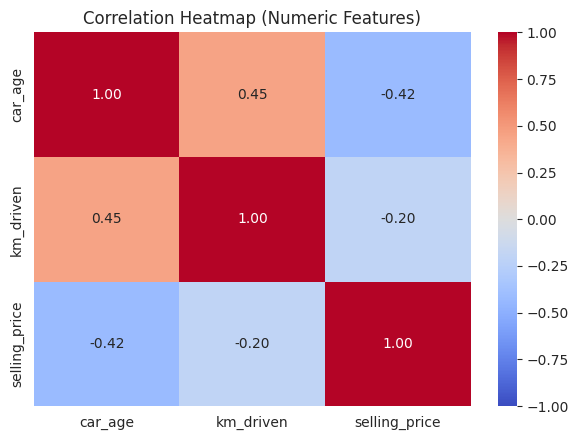

In [71]:
num_cols = ['car_age', 'km_driven', 'selling_price']
corr = df[num_cols].corr()
print(corr.round(3))

print('\nCorrelation with selling_price (sorted):')
print(corr['selling_price'].drop('selling_price').sort_values())

plt.figure(figsize=(6, 4.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Heatmap (Numeric Features)')
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/correlation_heatmap.png', dpi=150)
plt.show()

**Correlation analysis:**
- `car_age` vs `selling_price` = **-0.42**: a moderate negative correlation. Older cars sell for less because of depreciation. It is the strongest numeric driver of price.
- `km_driven` vs `selling_price` = **-0.20**: a weak negative correlation. Higher mileage means more wear, so the price drops, but the effect is smaller than age.
- `car_age` vs `km_driven` = **0.45**: older cars have usually been driven more, so the two features partly overlap. This is moderate, not severe, so both can stay in the model.
- Neither correlation is very strong, which tells us that categorical features (brand, fuel, transmission) matter a lot too.

### 3.3 Visualizations

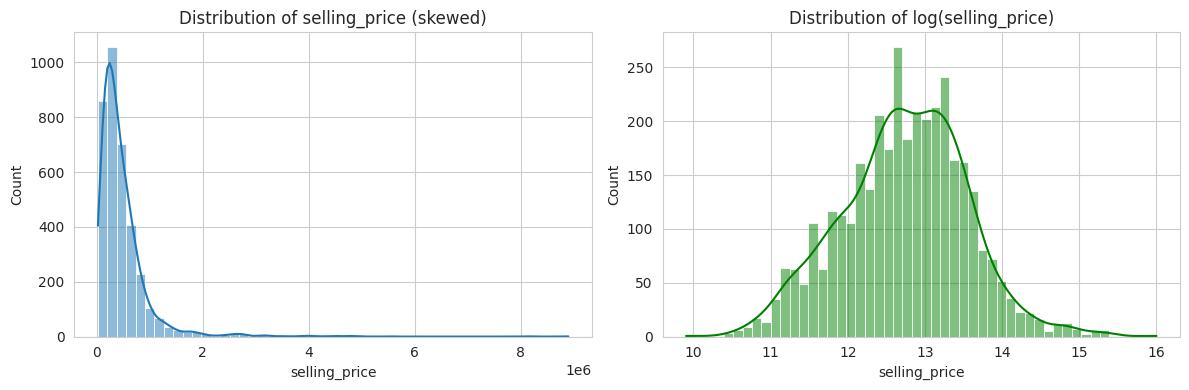

In [72]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['selling_price'], bins=50, kde=True, ax=ax[0])
ax[0].set_title('Distribution of selling_price (skewed)')
sns.histplot(np.log1p(df['selling_price']), bins=50, kde=True, ax=ax[1], color='green')
ax[1].set_title('Distribution of log(selling_price)')
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/price_distribution.png', dpi=150)
plt.show()

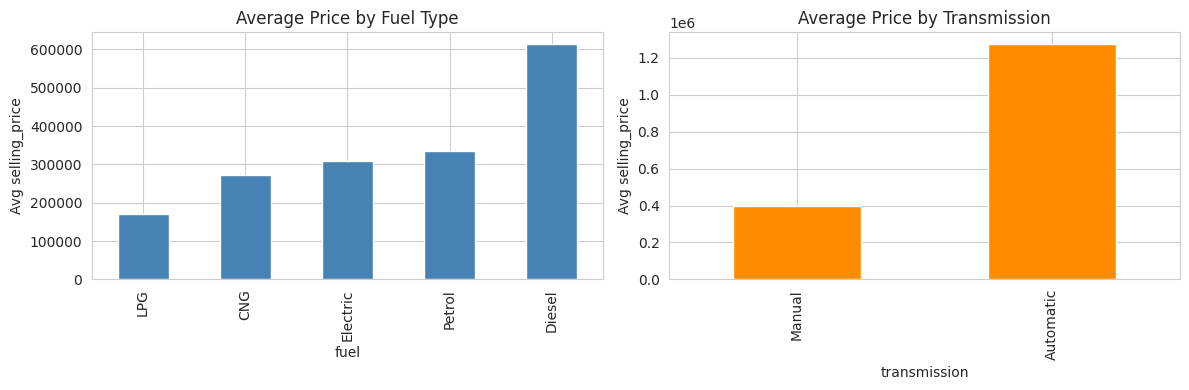

In [73]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df.groupby('fuel')['selling_price'].mean().sort_values().plot(kind='bar', ax=ax[0], color='steelblue')
ax[0].set_title('Average Price by Fuel Type'); ax[0].set_ylabel('Avg selling_price')
df.groupby('transmission')['selling_price'].mean().sort_values().plot(kind='bar', ax=ax[1], color='darkorange')
ax[1].set_title('Average Price by Transmission'); ax[1].set_ylabel('Avg selling_price')
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/avg_price_fuel_transmission.png', dpi=150)
plt.show()

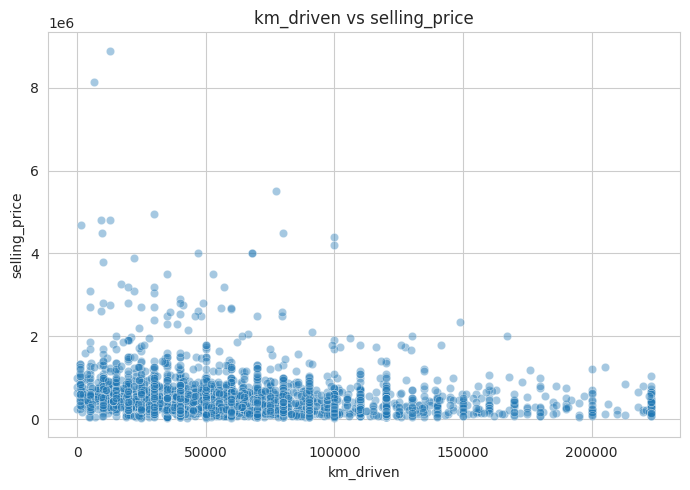

In [74]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x='km_driven', y='selling_price', alpha=0.4)
plt.title('km_driven vs selling_price')
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/km_vs_price_scatter.png', dpi=150)
plt.show()

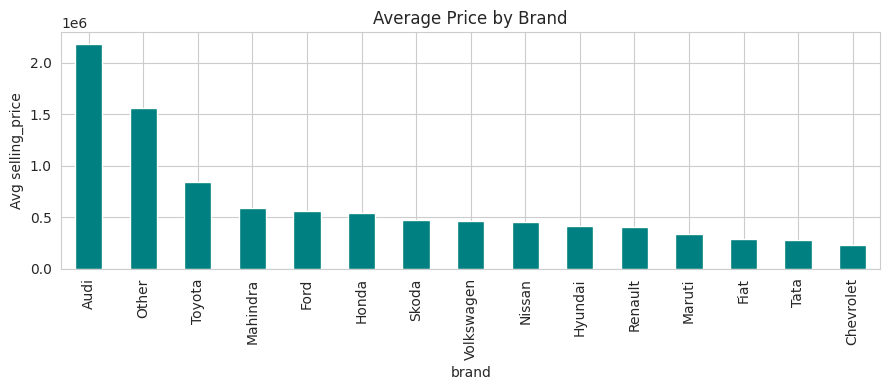

In [75]:
plt.figure(figsize=(9, 4))
df.groupby('brand')['selling_price'].mean().sort_values(ascending=False).plot(kind='bar', color='teal')
plt.title('Average Price by Brand'); plt.ylabel('Avg selling_price')
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/avg_price_brand.png', dpi=150)
plt.show()

**EDA observations:**
- `selling_price` is right-skewed (a few expensive cars), and the log transform makes it much closer to normal.
- Diesel cars have the highest average price among fuel types, and automatic cars cost far more on average than manual cars.
- Premium brands (Audi and the grouped 'Other' brands such as BMW and Mercedes) have far higher average prices than mass-market brands like Maruti and Tata.
- Price tends to fall as `km_driven` rises, but with a lot of spread (weak correlation).

## 4. Feature Engineering

`car_age` (created in 3.1) and `brand` (created during cleaning)

In [76]:
# Log-transform the skewed target
df['log_price'] = np.log1p(df['selling_price'])

# One-hot encode categorical columns
cat_cols = ['fuel', 'seller_type', 'transmission', 'owner', 'brand']
df_model = pd.get_dummies(df, columns=cat_cols, drop_first=True)
print(df_model.shape)
df_model.head()

(3577, 29)


,selling_price,km_driven,car_age,log_price,fuel_Diesel,fuel_Electric,fuel_LPG,fuel_Petrol,seller_type_Individual,seller_type_Trustmark Dealer,...,brand_Hyundai,brand_Mahindra,brand_Maruti,brand_Nissan,brand_Other,brand_Renault,brand_Skoda,brand_Tata,brand_Toyota,brand_Volkswagen
0,60000,70000.0,19,11.002117,False,False,False,True,True,False,...,False,False,True,False,False,False,False,False,False,False
1,135000,50000.0,19,11.813037,False,False,False,True,True,False,...,False,False,True,False,False,False,False,False,False,False
2,600000,100000.0,14,13.304687,True,False,False,False,True,False,...,True,False,False,False,False,False,False,False,False,False
3,250000,46000.0,9,12.429220,False,False,False,True,True,False,...,False,False,False,False,True,False,False,False,False,False
4,450000,141000.0,12,13.017005,True,False,False,False,True,False,...,False,False,False,False,False,False,False,False,False,False


**Ranking all features by correlation with price** (numeric and one-hot encoded)

transmission_Manual      -0.486
car_age                  -0.424
brand_Other               0.375
fuel_Diesel               0.277
fuel_Petrol              -0.261
km_driven                -0.201
seller_type_Individual   -0.188
brand_Maruti             -0.182
brand_Toyota              0.160
owner_Second Owner       -0.159
Name: selling_price, dtype: float64


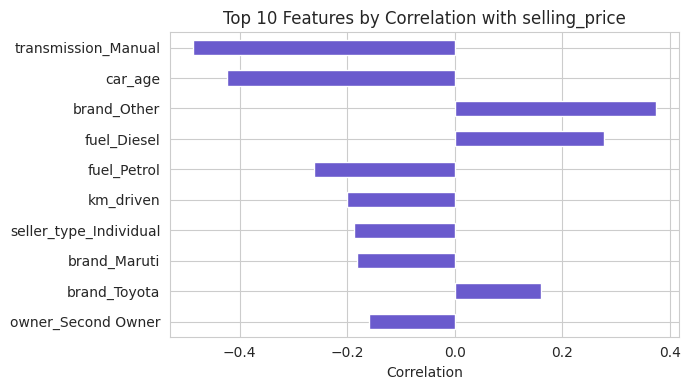

In [77]:
corr_all = df_model.drop(columns=['log_price']).astype(float).corr()['selling_price'].drop('selling_price')
top = corr_all.reindex(corr_all.abs().sort_values(ascending=False).index)
print(top.head(10).round(3))

plt.figure(figsize=(7, 4))
top.head(10)[::-1].plot(kind='barh', color='slateblue')
plt.title('Top 10 Features by Correlation with selling_price')
plt.xlabel('Correlation')
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/top_correlated_features.png', dpi=150)
plt.show()

## 5. Model Building

In [78]:
X = df_model.drop(columns=['selling_price', 'log_price'])
y = df_model['log_price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('Train:', X_train.shape, '| Test:', X_test.shape)

model = LinearRegression()
model.fit(X_train, y_train)
y_pred_log = model.predict(X_test)

Train: (2861, 27) | Test: (716, 27)


## 6. Evaluation

In [79]:
y_pred = np.expm1(y_pred_log)
y_actual = np.expm1(y_test)

r2 = r2_score(y_actual, y_pred)
r2_log = r2_score(y_test, y_pred_log)
mae = mean_absolute_error(y_actual, y_pred)
rmse = np.sqrt(mean_squared_error(y_actual, y_pred))

print(f'R2 (original price scale): {r2:.4f}')
print(f'R2 (log price scale)     : {r2_log:.4f}')
print(f'MAE : {mae:,.0f}')
print(f'RMSE: {rmse:,.0f}')

R2 (original price scale): 0.5765
R2 (log price scale)     : 0.7652
MAE : 153,733
RMSE: 369,340


**Interpretation of the metrics:**
- **R2 = 0.58** (original price scale) and **0.77** (log scale): the model explains about 58% of the variation in actual prices, and about 77% of the variation in log-prices. The score is lower in rupees because a few very expensive cars are hard to predict.
- **MAE ≈ 1.54 lakh:** on average the predicted price is off by about Rs 1.5 lakh.
- **RMSE ≈ 3.69 lakh:** RMSE is much larger than MAE because it penalises big mistakes, which come from expensive cars. This shows the model is reliable for typical cars but less accurate for luxury ones.


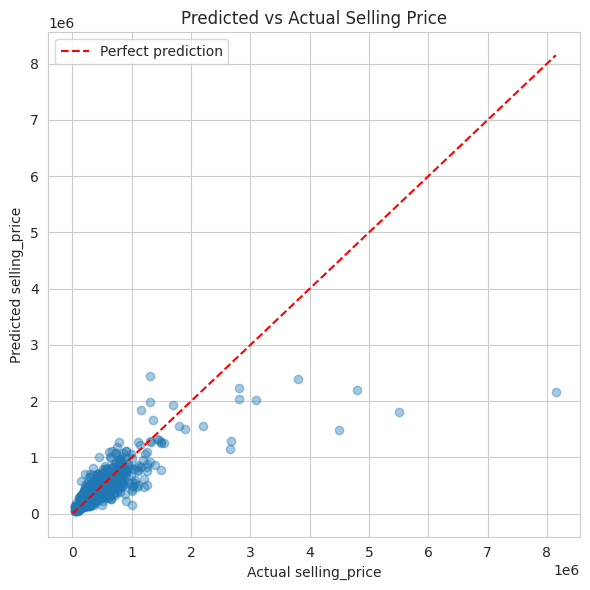

In [80]:
plt.figure(figsize=(6, 6))
plt.scatter(y_actual, y_pred, alpha=0.4)
lims = [0, max(y_actual.max(), y_pred.max())]
plt.plot(lims, lims, 'r--', label='Perfect prediction')
plt.xlabel('Actual selling_price'); plt.ylabel('Predicted selling_price')
plt.title('Predicted vs Actual Selling Price'); plt.legend()
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/predicted_vs_actual.png', dpi=150)
plt.show()

## 7. Insights & Summary

- **Features most correlated with price:** `car_age` (-0.42) and `km_driven` (-0.20) are the strongest numeric features. Older and higher-mileage cars sell for less because of depreciation and wear. Among the categorical features, transmission, fuel type and brand also show a clear effect (see the feature ranking in section 4).
- Log-transforming `selling_price` made the target closer to normal, which suits a linear model.
- **Final metrics:** R2 = 0.58 (price scale) / 0.77 (log scale), MAE ≈ 153,733, RMSE ≈ 369,340.
- **Business takeaway:** sellers can use the model for a realistic starting price, and buyers can treat a listing priced far above the prediction as possibly overpriced.
- **Limitations:** Linear Regression cannot capture non-linear effects and struggles with luxury cars; Random Forest would likely perform better.